In [1]:
import numpy as np

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import AdditiveTransitionModel
from particle_filter.models.observation import AdditiveObservationModel
from particle_filter.simulations import system_simulation

from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter

from particle_filter.plots.plot_results import plot_results

C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_filter.py:137: SyntaxWarning: invalid escape sequence '\s'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_filter.py:237: SyntaxWarning: invalid escape sequence '\;'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_filter.py:305: SyntaxWarning: invalid escape sequence '\m'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_filter.py:311: SyntaxWarning: invalid escape sequence '\h'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_filter.py:322: SyntaxWarning: invalid escape sequence '\p'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_filter.py:348: SyntaxWarning: invalid escape sequence '\s'
  """
C:\Users\usuario\Desktop\Particle_Filter\particle_filter\filtering_algorithms\particle_f

# ATRACTOR DE LORENZ

El atractor de Lorenz es un sistema dinámico que muestra un comportamiento caótico para ciertos valores de sus parámetros $a,b,c$.

El sistema está formado por las ecuaciones

$$
\begin{align*}
\frac{dx}{dt}&= a(y-x) \\
\frac{dx}{dt}&= x(b-z) - y \\
\frac{dz}{dt}&= xy - cz
\end{align*}
$$

El sistema presenta un comportamiento caótico para $a=10,\; b=28$ y $c=8/3$.

Dado que se trabaja con el tiempo discreto, se realiza la aproximación numérica de Euler:

$$
x´(t)\approx \frac{x_{n+1} - x_n}{\Delta t} 
$$

y despejando:

$$
x_{n+1} = x_n + \Delta t \;x´(t_n)
$$

Así, las ecuaciones discretizadas del atractor de Lorentz quedan: 

$$
\textbf{x}_{k+1} = \textbf{x}_k + \Delta t 
\begin{bmatrix}
10.0 \cdot (y_k - x_k) \\   
x_k \cdot (28.0 - z_k) - y_k \\ 
x_k \cdot y_k - 8/3 \cdot z_k
\end{bmatrix}
$$

Se va a suponer que solo se observa la primera coordenada del estado:

$$
y_k = H \textbf{x}_k \quad\quad \text{H = [1 0 0]}
$$

### Ecuación en espacio de estados

Finalmente, introduciendo el ruido del proceso dinámico y el ruido de medición, se construye modelo en espacio de estados

- Vector estado

$$
\textbf{x}_k = 
\begin{bmatrix}
x_k \\
y_k \\
z_k
\end{bmatrix}
$$

- Modelo dinámico

$$
\textbf{x}_{k+1} = \textbf{x}_k + \Delta t 
\begin{bmatrix}
10.0 \cdot (y_k - x_k) \\   
x_k \cdot (28.0 - z_k) - y_k \\ 
x_k \cdot y_k - 8/3 \cdot z_k
\end{bmatrix} 
+ w_k
$$

- Modelo de medición

$$
y_k = [1\quad 0\quad 0]\;\textbf{x}_k + v_k
$$

con 

$$
w_k \sim \mathcal{N}(0, Q)\quad \quad v_k \sim \mathcal{N}(0, R)\\\\[2ex]

Q = \begin{bmatrix}

10^{-3} &0 &0 \\
0 &10^{-3} &0 \\
0 &0 &10^{-3}
\end{bmatrix}

\quad \quad

R = \begin{bmatrix} 1 \end{bmatrix}
$$

In [28]:
# Parámetros
a = 10.0
b = 28.0
c = 8/3

dt = 0.1

In [ ]:
# Definición función de transición
def lorenz(x):
    x1, x2, x3 = x

    return np.array([
        a * (x2 - x1),
        x1 * (b - x3) - x2,
        x1 * x2 - c * x3
    ])

In [30]:
def f(x):
    k1 = lorenz(x)
    k2 = lorenz(x + 0.5 * dt * k1)
    k3 = lorenz(x + 0.5 * dt * k2)
    k4 = lorenz(x + dt * k3)

    return x + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

In [31]:
# Definición función de medición 
def h(x):
    x1, _, _ = x

    return np.array([x1])

In [32]:
# Definición de ruidos 
Q = np.diag([1e-3, 1e-3, 1e-3]) # ruido de proceso
R = np.array([1.0]) # ruido de observación

In [33]:
# Definición modelos
noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation)

In [34]:
# Simulación
T = 500
x0 = np.array([1.0, 1.0, 1.0])

x_true, y_obs = system_simulation(transition, observation, x0, T)

In [35]:
#Iniciar Bootstrap Particle Filter
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

bpf.initialize(mean=np.array([1.0, 1.0, 1.0]), cov=0.5 * np.eye(3))

In [36]:
#Ejecucion Bootstrap Particle Filter
est_bpf = bpf.run_filter(y_obs, resample_threshold=500)

log_weights
min = -24.278897645230348
max = -5.289513090826528
nan = False
inf = False
sum = 0.9999999999999996
nan = False
inf = False
ESS = 364.03623605319797
log_weights
min = -28.643019216190034
max = -5.93655422566673
nan = False
inf = False
log_weights
min = -145.09595812250268
max = -4.868007707064053
nan = False
inf = False
sum = 0.9999999999999997
nan = False
inf = False
ESS = 176.47413180040994
log_weights
min = -20.24489712611612
max = -6.420424797989391
nan = False
inf = False
log_weights
min = -32.05994093281629
max = -6.120953204892127
nan = False
inf = False
log_weights
min = -68.90801569951081
max = -5.615100226472115
nan = False
inf = False
sum = 1.0
nan = False
inf = False
ESS = 481.65586193128274
log_weights
min = -9.612627397359592
max = -6.331994732978032
nan = False
inf = False
log_weights
min = -11.167094874278357
max = -6.088053882968775
nan = False
inf = False
log_weights
min = -11.435656059800255
max = -6.080560628701499
nan = False
inf = False
log_weights
min

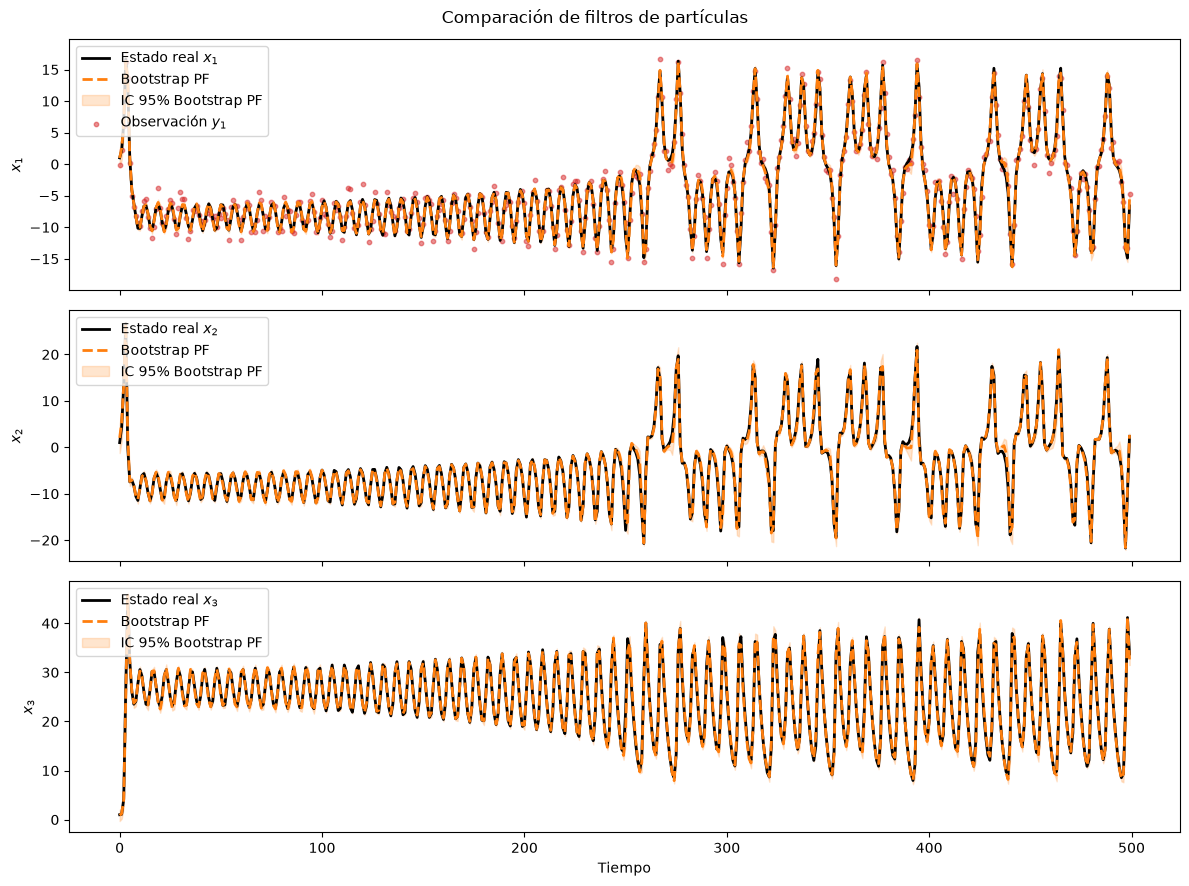

In [38]:
estimate_bpf = { "Bootstrap PF": est_bpf["estimates"] }
confidence_bpf = { "Bootstrap PF": est_bpf["intervals"] }

plot_results(x_true, y_obs, estimate_bpf, confidence_bpf)

In [50]:
# Resultados Bootstrap Particle Filter
metrics = ["number_particles", "number_resamples", "execution_time", "log_likelihood"]

for key in est_bpf.keys():
    if key in metrics:
        print(f"{key} Bootstrap PF: {est_bpf[key]}")

number_particles Bootstrap PF: 1000
number_resamples Bootstrap PF: 247
execution_time Bootstrap PF: 487.03799599967897
log_likelihood Bootstrap PF: -7235.7308786784815


In [51]:
apf = AuxiliaryParticleFilter(
    N=1000, 
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=np.array([1.0, 1.0, 1.0]), cov=0.5 * np.eye(3))

In [52]:
est_apf = apf.run_filter(y_obs, resample_threshold=500)

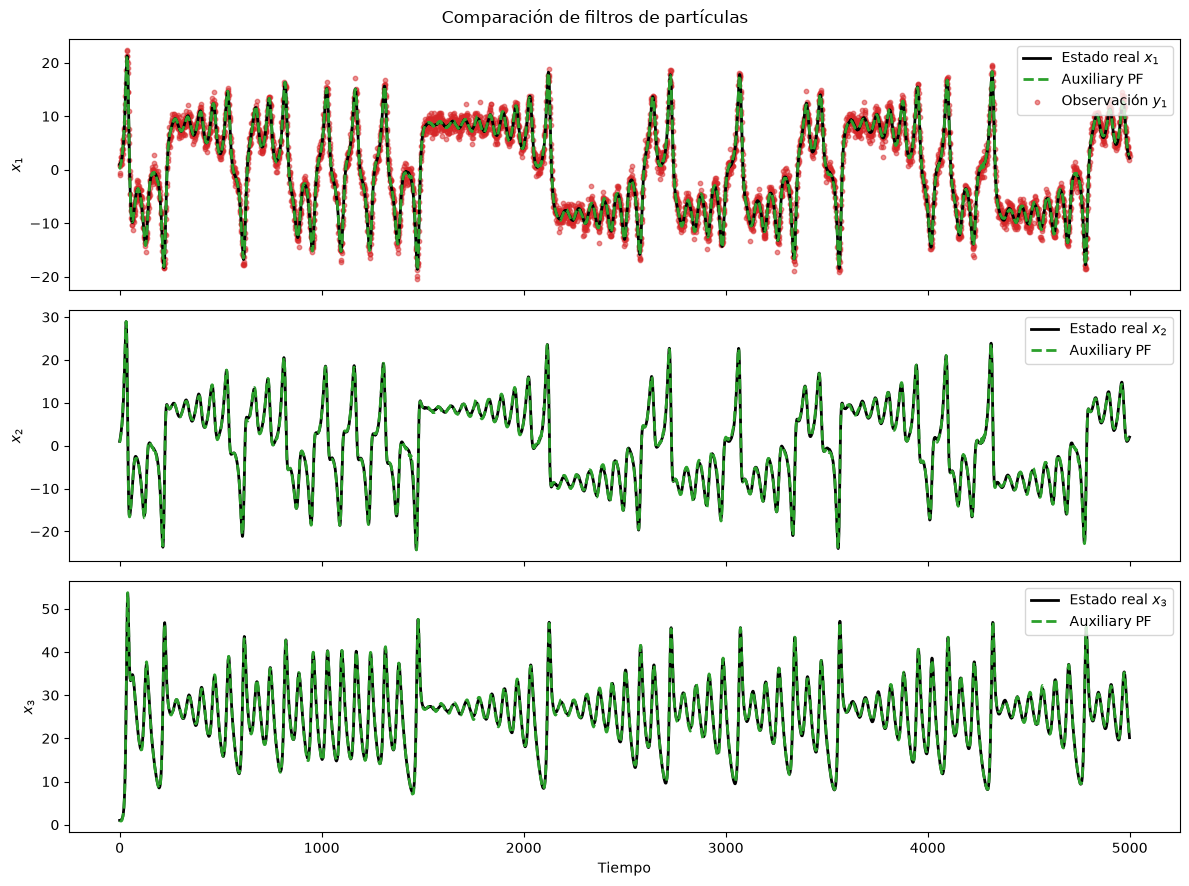

In [53]:
estimate_apf = { "Auxiliary PF": est_apf["estimates"] }
confidence_apf = { "Auxiliary  PF": est_apf["intervals"] }

plot_results(x_true, y_obs, estimate_apf, confidence_apf)

In [54]:
# Resultados Auxiliary Particle Filter
metrics = ["number_particles", "number_resamples", "execution_time", "log_likelihood"]

for key in est_apf.keys():
    if key in metrics:
        print(f"{key} Auxiliary PF: {est_apf[key]}")

number_particles Auxiliary PF: 1000
number_resamples Auxiliary PF: 0
execution_time Auxiliary PF: 1090.283643799834
log_likelihood Auxiliary PF: -7245.6079193049345


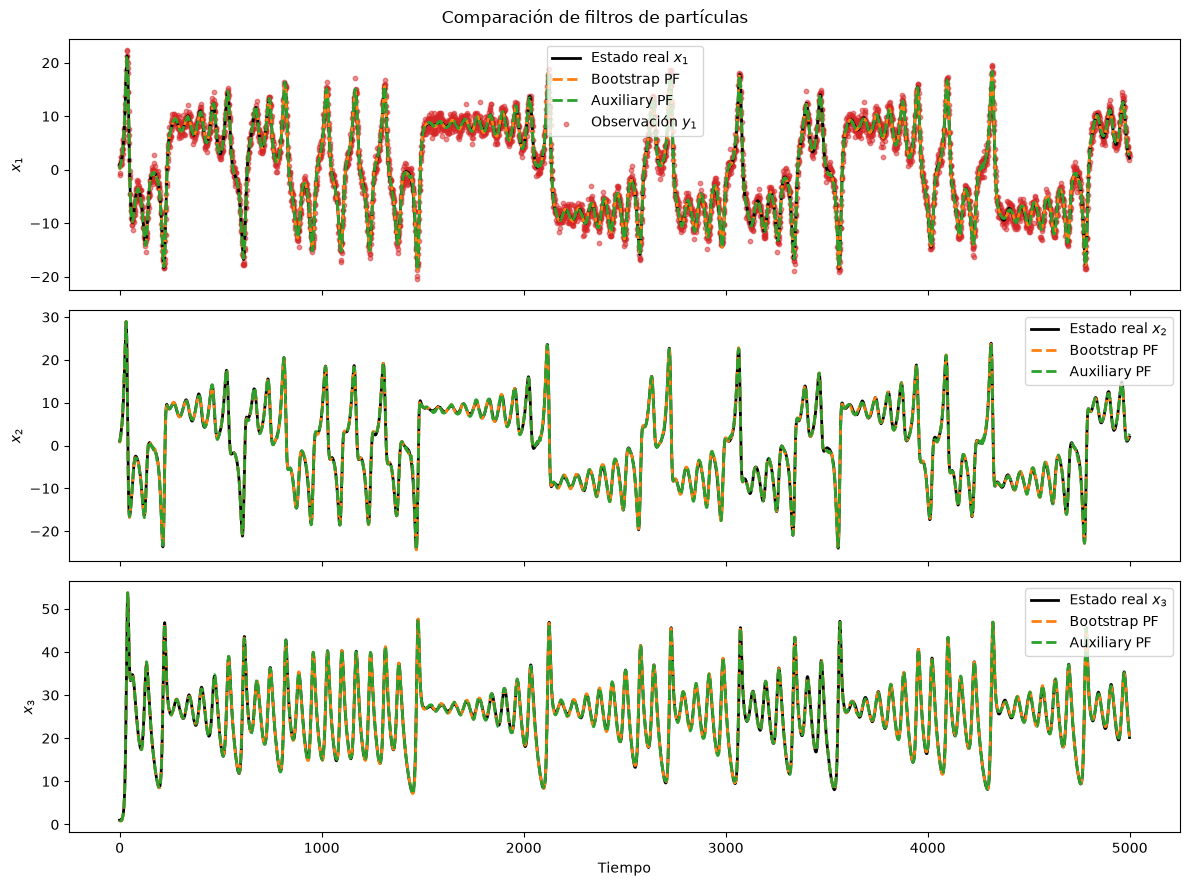

In [55]:
estimates = {
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"]
}

plot_results(x_true, y_obs, estimates)